In [1]:
from itertools import islice
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def uniform_triangle(u, v):
    while True:
        s = np.random.uniform()
        t = np.random.uniform()
        in_triangle = s + t <= 1
        p = s * u + t * v if in_triangle else (1 - s) * u + (1 - t) * v
        yield p


triangle_set1 = [
    np.array([[0, 0], [0.5, 0.5], [0, 0.5]]),
    np.array([[0.5, 0.5], [0, 0.5], [0, 1.0]]),
]
triangle_set2 = [np.concatenate((a[:, 1:2], a[:, 0:1]), axis=1) for a in triangle_set1]

triangle_set = triangle_set1 + triangle_set2

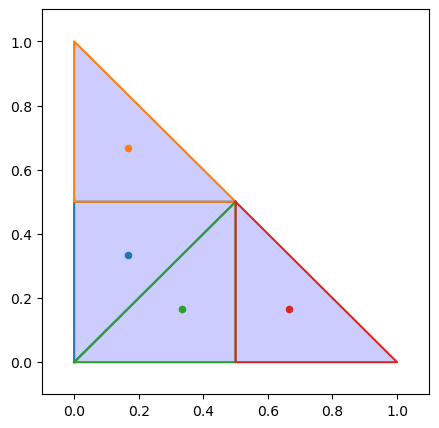

In [2]:
np.random.seed(42)

fig, ax = plt.subplots(figsize=(5, 5))
point_total = []

for triangle in triangle_set:
    # draw the triangle
    x_coords, y_coords = zip(*triangle)
    # Close the triangle by adding the first vertex at the end
    x_coords += (x_coords[0],)
    y_coords += (y_coords[0],)

    # Create the plot
    ax.plot(x_coords, y_coords)  # 'o' for circle markers at the vertices
    ax.fill(
        x_coords, y_coords, "b", alpha=0.2
    )  # Fill the triangle with a blue color and some transparency

    it = uniform_triangle(
        triangle[1] - triangle[0],
        triangle[2] - triangle[0],
    )
    points = triangle.mean(axis=0).reshape(-1, 2)

    ax.scatter(points[:, 0], points[:, 1], s=20)
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)

    point_total.append(points)

point_total.append(np.array([[1,0]]))
point_total.append(np.array([[0,1]]))
point_total = np.concatenate(point_total)

In [3]:
metal_combo = np.array(
    [
        ["Fe", "Co"]
    ]
)

np.random.seed(42)
candidates_total = []
for metal_combo_temp in metal_combo:
    a_temp = point_total.copy()
    b_temp = np.random.uniform(low = 0, high = 1 - (point_total).sum(axis = 1))

    c_temp = np.random.uniform(low = 0, high = 1 - (point_total).sum(axis = 1) - b_temp)

    candidates = np.around(
        np.concatenate((a_temp * 18 + 1.0, 18*(b_temp).reshape(-1,1), 18*(c_temp).reshape(-1,1)), axis=1), 2
    )
    
    water = (20 - candidates.sum(axis=1)).reshape(-1, 1)
    candidates = np.concatenate((candidates, water), axis=1)
    candidates_total.append(candidates)
    print(metal_combo_temp)
    print(candidates)

['Fe' 'Co']
[[ 4.    7.    3.37  0.33  5.3 ]
 [ 4.   13.    2.85  0.13  0.02]
 [ 7.    4.    6.59  1.45  0.96]
 [13.    4.    1.8   0.85  0.35]
 [19.    1.    0.    0.    0.  ]
 [ 1.   19.    0.    0.    0.  ]]


In [7]:
_all_candidates = []
# export the json file
# set a repeat experiment as a reference
repeat_exp = pd.DataFrame(
    {
        "substance1": ["Fe"],
        "volume1": [20*2/10],
        "substance2": ["Co"],
        "volume2": [20*2/10],
        "substance3": ["Na3Cit"],
        "volume3": [20*2/10],
        "substance4": ["NaH2PO2"],
        "volume4": [20*2/10],
        "substance5": ["water"],
        "volume5": [20*2/10],
        
        "syn_completed": ["None"],
        "storage_location": ["None"],
        "in_storage": ["None"],
        "cat_completed": ["None"], 
        
        "lsv_overpotential_-0.01": ["None"],
        "lsv_overpotential_-0.02": ["None"],
        "lsv_overpotential_-0.03": ["None"],
        "lsv_overpotential_-0.04": ["None"],
        "lsv_overpotential_-0.05": ["None"],

        "lsv_overpotential_0.01": ["None"],
        "lsv_overpotential_0.02": ["None"],
        "lsv_overpotential_0.03": ["None"],
        "lsv_overpotential_0.04": ["None"],
        "lsv_overpotential_0.05": ["None"],

        "mass_time_start": ["None"],
        "mass_time_end": ["None"],
        "separation_coefficient":["None"]
    }
)

repeat_index = [0]

# write the new candidates to the excel for the closed-loop discovery
exp_data_out = {}
exp_data_out["substance1"] = []
exp_data_out["volume1"] = []
exp_data_out["substance2"] = []
exp_data_out["volume2"] = []
exp_data_out["substance3"] = []
exp_data_out["volume3"] = []
exp_data_out["substance4"] = []
exp_data_out["volume4"] = []
exp_data_out["substance5"] = []
exp_data_out["volume5"] = []

exp_data_out["syn_completed"] = []
exp_data_out["storage_location"] = []
exp_data_out["in_storage"] = []

exp_data_out["cat_completed"] = []
exp_data_out["lsv_overpotential_-0.01"] = []
exp_data_out["lsv_overpotential_-0.02"] = []
exp_data_out["lsv_overpotential_-0.03"] = []
exp_data_out["lsv_overpotential_-0.04"] = []
exp_data_out["lsv_overpotential_-0.05"] = []

exp_data_out["lsv_overpotential_0.01"] = []
exp_data_out["lsv_overpotential_0.02"] = []
exp_data_out["lsv_overpotential_0.03"] = []
exp_data_out["lsv_overpotential_0.04"] = []
exp_data_out["lsv_overpotential_0.05"] = []

exp_data_out["mass_time_start"] = []
exp_data_out["mass_time_end"] = []
exp_data_out["separation_coefficient"] = []

exp_data_out = pd.DataFrame(exp_data_out)

for candidate_index in range(len(candidates_total[0])):
    metal_index = 0
    if len(exp_data_out)%4 ==3:
        exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)

    temp = pd.DataFrame(
        {
            "substance1": [metal_combo[metal_index][0]],
            "volume1": [candidates_total[metal_index][candidate_index][0]],

            "substance2": [metal_combo[metal_index][1]],
            "volume2": [candidates_total[metal_index][candidate_index][1]],

            "substance3": "Na3Cit",
            "volume3": [candidates_total[metal_index][candidate_index][2]],

            "substance4": "NaH2PO2",
            "volume4": [candidates_total[metal_index][candidate_index][3]],

            "substance5": "water",
            "volume5": [candidates_total[metal_index][candidate_index][4]],

            "syn_completed": ["None"],
            "storage_location": ["None"],
            "in_storage": ["None"],
            "cat_completed": ["None"], 

            "lsv_overpotential_-0.01": ["None"],
            "lsv_overpotential_-0.02": ["None"],
            "lsv_overpotential_-0.03": ["None"],
            "lsv_overpotential_-0.04": ["None"],
            "lsv_overpotential_-0.05": ["None"],

            "lsv_overpotential_0.01": ["None"],
            "lsv_overpotential_0.02": ["None"],
            "lsv_overpotential_0.03": ["None"],
            "lsv_overpotential_0.04": ["None"],
            "lsv_overpotential_0.05": ["None"],

            "mass_time_start": ["None"],
            "mass_time_end": ["None"],
            "separation_coefficient":["None"]
        }
    )

    for repeat in range(1):
        exp_data_out = pd.concat((exp_data_out, temp), ignore_index=True)
            
    # if len(exp_data_out) in repeat_index:
    #     exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)
exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)
display(exp_data_out)
exp_data_out.to_json(f"./initial_sampling_Fe_Co.json", indent = 4)

,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,...,lsv_overpotential_-0.04,lsv_overpotential_-0.05,lsv_overpotential_0.01,lsv_overpotential_0.02,lsv_overpotential_0.03,lsv_overpotential_0.04,lsv_overpotential_0.05,mass_time_start,mass_time_end,separation_coefficient
0,Fe,4.0,Co,7.0,Na3Cit,3.37,NaH2PO2,0.33,water,5.30,...,None,None,None,None,None,None,None,None,None,None
1,Fe,4.0,Co,13.0,Na3Cit,2.85,NaH2PO2,0.13,water,0.02,...,None,None,None,None,None,None,None,None,None,None
2,Fe,7.0,Co,4.0,Na3Cit,6.59,NaH2PO2,1.45,water,0.96,...,None,None,None,None,None,None,None,None,None,None
3,Fe,4.0,Co,4.0,Na3Cit,4.00,NaH2PO2,4.00,water,4.00,...,None,None,None,None,None,None,None,None,None,None
4,Fe,13.0,Co,4.0,Na3Cit,1.80,NaH2PO2,0.85,water,0.35,...,None,None,None,None,None,None,None,None,None,None
5,Fe,19.0,Co,1.0,Na3Cit,0.00,NaH2PO2,0.00,water,0.00,...,None,None,None,None,None,None,None,None,None,None
6,Fe,1.0,Co,19.0,Na3Cit,0.00,NaH2PO2,0.00,water,0.00,...,None,None,None,None,None,None,None,None,None,None
7,Fe,4.0,Co,4.0,Na3Cit,4.00,NaH2PO2,4.00,water,4.00,...,None,None,None,None,None,None,None,None,None,None
